<a href="https://colab.research.google.com/github/Wrdone/MH/blob/main/%D0%9B%D0%A0_8_%D0%9B%D1%83%D0%BA'%D1%8F%D0%BD_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

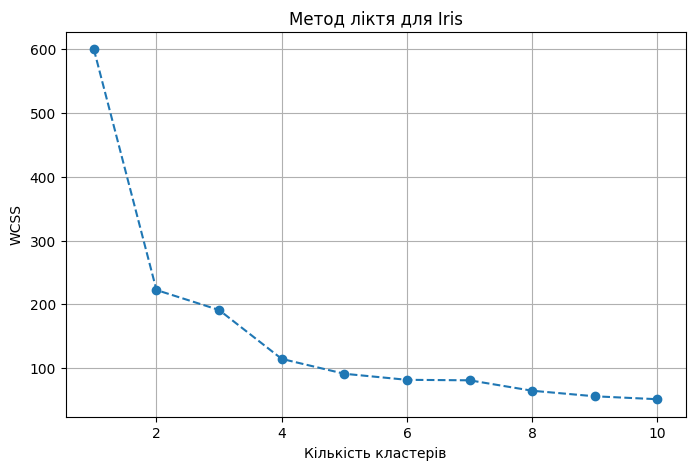

In [ ]:
# Стандартизація даних
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(df_iris)

# Метод ліктя
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init='auto')
    kmeans.fit(X_iris_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Метод ліктя для Iris')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

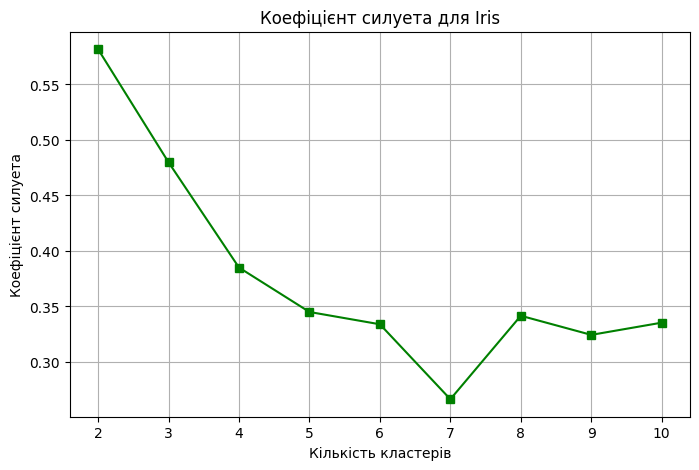

In [ ]:
# Обчислення коефіцієнта силуета для 2-10 кластерів
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init='auto')
    kmeans.fit(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, kmeans.labels_)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='s', color='green', linestyle='-')
plt.title('Коефіцієнт силуета для Iris')
plt.xlabel('Кількість кластерів')
plt.ylabel('Коефіцієнт силуета')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

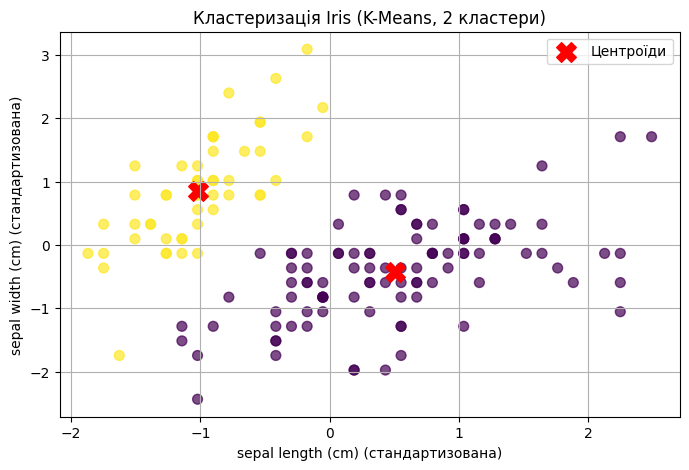

In [ ]:
# Будуємо модель для 2 кластерів
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init='auto')
clusters_iris = kmeans_final.fit_predict(X_iris_scaled)
centroids = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=clusters_iris, cmap='viridis', s=50, alpha=0.7)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Центроїди')
plt.title('Кластеризація Iris (K-Means, 2 кластери)')
plt.xlabel(df_iris.columns[0] + ' (стандартизована)')
plt.ylabel(df_iris.columns[1] + ' (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
# Формуємо X та y
X_clf = df.drop(columns=['StudentID', 'GradeClass'])
y_clf = df['GradeClass']

# Поділ на тренувальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

# Стандартизація
scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled = scaler_clf.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
rf_params = {'n_estimators': [50, 100], 'max_depth': [None, 5, 10]}
rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

print("Найкращі параметри Random Forest:", rf_grid.best_params_)
print(f"Середня CV-точність: {rf_grid.best_score_:.4f}")
rf_test_acc = accuracy_score(y_test, rf_grid.predict(X_test_scaled))
print(f"Тестова accuracy: {rf_test_acc:.4f}")

Найкращі параметри Random Forest: {'max_depth': 10, 'n_estimators': 100}
Середня CV-точність: 0.9190
Тестова accuracy: 0.9123


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
lr_params = {'C': [0.1, 1, 10], 'penalty': ['l1', 'l2']}
# Використовуємо solver='saga' для мультикласової класифікації
lr = LogisticRegression(solver='saga', multi_class='multinomial', max_iter=2000, random_state=42)
lr_grid = GridSearchCV(lr, lr_params, cv=5, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

print("Найкращі параметри Logistic Regression:", lr_grid.best_params_)
print(f"Середня CV-точність: {lr_grid.best_score_:.4f}")
lr_test_acc = accuracy_score(y_test, lr_grid.predict(X_test_scaled))
print(f"Тестова accuracy: {lr_test_acc:.4f}")

Найкращі параметри Logistic Regression: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.8024
Тестова accuracy: 0.8184


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
svc = SVC(random_state=42)
svm_grid = GridSearchCV(svc, svm_params, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

print("Найкращі параметри SVM:", svm_grid.best_params_)
print(f"Середня CV-точність: {svm_grid.best_score_:.4f}")
svm_test_acc = accuracy_score(y_test, svm_grid.predict(X_test_scaled))
print(f"Тестова accuracy: {svm_test_acc:.4f}")

Найкращі параметри SVM: {'C': 10, 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
print(f"Тестова точність (Accuracy) - RF: {rf_test_acc:.4f} | LR: {lr_test_acc:.4f} | SVM: {svm_test_acc:.4f}")

# Обираємо найкращу модель за CV-точністю
cv_scores = {'Random Forest': rf_grid.best_score_, 'Logistic Regression': lr_grid.best_score_, 'SVM': svm_grid.best_score_}
best_model_name = max(cv_scores, key=cv_scores.get)
print(f"\nНайкраща модель за CV-точністю: {best_model_name}")

# Відповідна модель для звіту
best_model = rf_grid if best_model_name == 'Random Forest' else (lr_grid if best_model_name == 'Logistic Regression' else svm_grid)

# Виводимо classification_report на тестових даних
y_pred_best = best_model.predict(X_test_scaled)
print("\nClassification Report (Test Data):")
print(classification_report(y_test, y_pred_best))

Тестова точність (Accuracy) - RF: 0.9123 | LR: 0.8184 | SVM: 0.8580

Найкраща модель за CV-точністю: Random Forest

Classification Report (Test Data):
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.87      0.85        54
         2.0       0.90      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.92      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

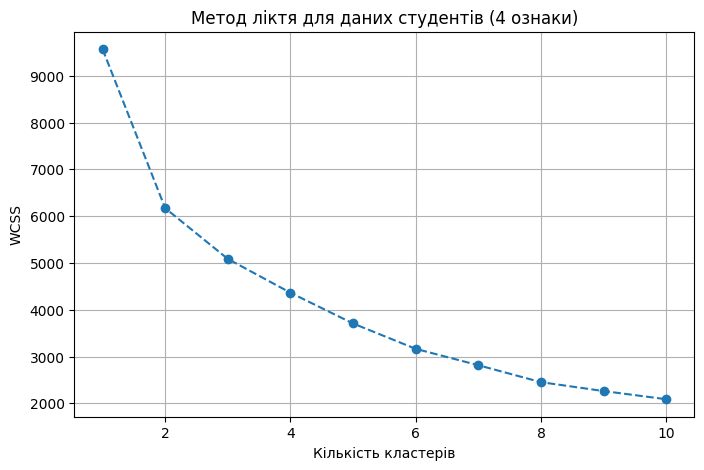

In [ ]:
# Відбір 4 числових ознак
features_clust = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stu = df[features_clust]

# Стандартизація
scaler_stu = StandardScaler()
X_stu_scaled = scaler_stu.fit_transform(X_stu)

# Метод ліктя
wcss_stu = []
for i in range(1, 11):
    kmeans_stu = KMeans(n_clusters=i, random_state=42, n_init='auto')
    kmeans_stu.fit(X_stu_scaled)
    wcss_stu.append(kmeans_stu.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_stu, marker='o', linestyle='--')
plt.title('Метод ліктя для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

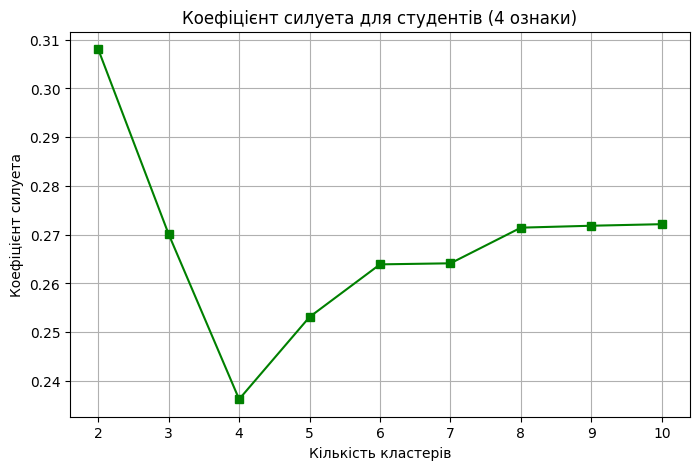

In [ ]:
sil_scores_stu = []
for i in range(2, 11):
    kmeans_stu = KMeans(n_clusters=i, random_state=42, n_init='auto')
    kmeans_stu.fit(X_stu_scaled)
    sil_scores_stu.append(silhouette_score(X_stu_scaled, kmeans_stu.labels_))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), sil_scores_stu, marker='s', color='green', linestyle='-')
plt.title('Коефіцієнт силуета для студентів (4 ознаки)')
plt.xlabel('Кількість кластерів')
plt.ylabel('Коефіцієнт силуета')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

pca = PCA(random_state=42)
pca.fit(X_all_scaled)

explained_variance = pca.explained_variance_ratio_
print("Частки поясненої дисперсії кожної компоненти:")
print(explained_variance)

Частки поясненої дисперсії кожної компоненти:
[0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальний індекс (від 0): 1
Оптимальна кількість компонент: 2


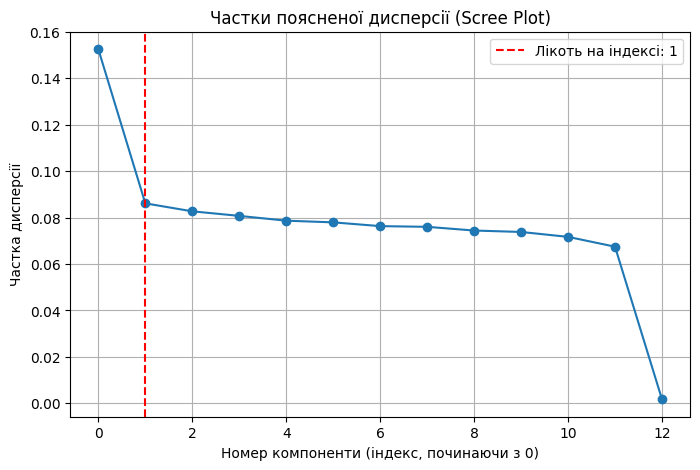

In [ ]:
# Оскільки компоненти нумеруються з 1, індекс для кожної n_components дорівнює n_components - 1
components_num = np.arange(1, len(explained_variance) + 1)
components_idx = components_num - 1

# Застосовуємо KneeLocator до часток поясненої дисперсії
kl = KneeLocator(components_idx, explained_variance, curve='convex', direction='decreasing')
optimal_idx = kl.elbow
optimal_components = optimal_idx + 1

print(f"Оптимальний індекс (від 0): {optimal_idx}")
print(f"Оптимальна кількість компонент: {optimal_components}")

plt.figure(figsize=(8, 5))
plt.plot(components_idx, explained_variance, marker='o')
plt.axvline(x=optimal_idx, color='r', linestyle='--', label=f'Лікоть на індексі: {optimal_idx}')
plt.title('Частки поясненої дисперсії (Scree Plot)')
plt.xlabel('Номер компоненти (індекс, починаючи з 0)')
plt.ylabel('Частка дисперсії')
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

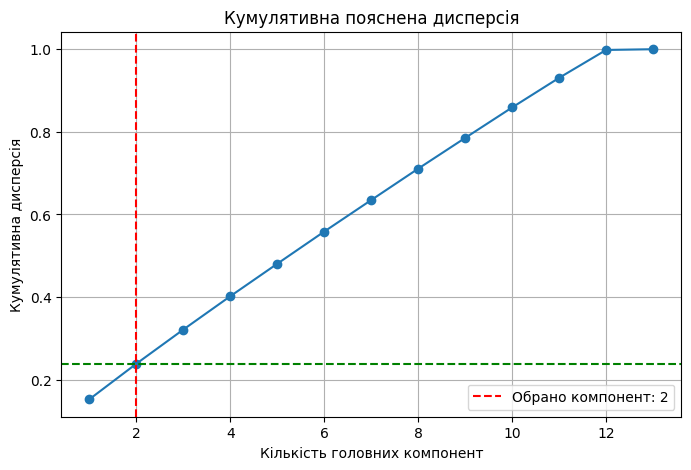

Фактична частка дисперсії для 2 компонент: 0.2386


In [ ]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(components_num, cumulative_variance, marker='o')
plt.axvline(x=optimal_components, color='r', linestyle='--', label=f'Обрано компонент: {optimal_components}')
plt.axhline(y=cumulative_variance[optimal_idx], color='g', linestyle='--')
plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна дисперсія')
plt.legend()
plt.grid(True)
plt.show()

print(f"Фактична частка дисперсії для {optimal_components} компонент: {cumulative_variance[optimal_idx]:.4f}")

# Перетворення даних за допомогою оптимальної кількості компонент
pca_optimal = PCA(n_components=optimal_components, random_state=42)
X_pca = pca_optimal.fit_transform(X_all_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

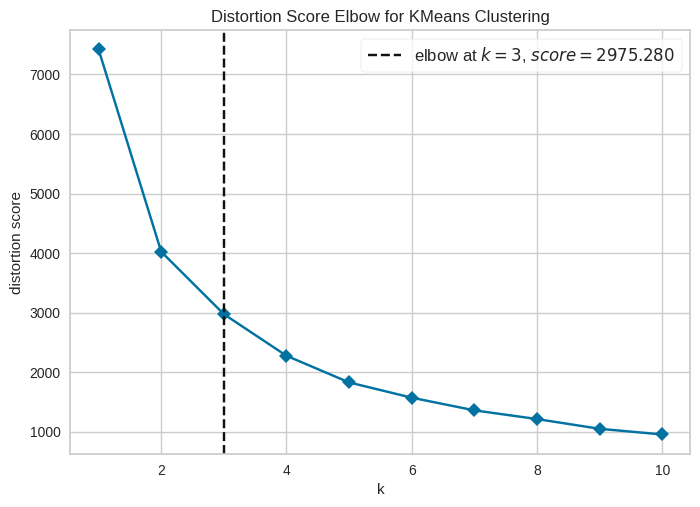

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
model = KMeans(random_state=42, n_init='auto')
# Будуємо візуалізатор для даних після PCA
visualizer = KElbowVisualizer(model, k=(1,11), timings=False)

visualizer.fit(X_pca)
visualizer.show()

## Висновки

Завдання 1: Кластеризація Iris

  Вибір двох кластерів (n_clusters=2) для датасету Iris зумовлений тим, що метод ліктя показав злам (зменшення темпів падіння WCSS) саме в цій точці. Метод силуетів також підтвердив цей вибір, показавши найвищий коефіцієнт для двох кластерів.

  Незважаючи на те, що датасет містить три види ірисів, два з них (Versicolor і Virginica) мають схожі характеристики, і алгоритм K-Means часто об'єднує їх в один більший кластер, тому обрання двох кластерів є логічним результатом роботи алгоритму без вчителя.

Завдання 2: Дослідження даних студентів (Класифікація)

  При порівнянні трьох моделей класифікації найкращою за точністю крос-валідації (CV) стала модель Random Forest (середня точність 91.90%).

  Модель SVM показала гірший, проте прийнятний результат (85.21%), а Logistic Regression виявилася найслабшою (80.24%). Цей результат вказує на те, що Random Forest краще справляється зі складними залежностями в цьому наборі даних.

Додаткове завдання: Кластеризація та використання PCA

  Кластеризація відрізняється від класифікації тим, що алгоритм самостійно знаходить приховані закономірності в даних без використання цільової змінної (GradeClass). У цьому завданні ми намагалися знайти природні групи студентів за їхніми характеристиками.

  Застосування алгоритму PCA дозволило зменшити розмірність датасету. Алгоритм KneeLocator автоматично визначив 2 оптимальні компоненти. Перші дві головні компоненти в сумі пояснюють близько 23,8% інформативності, що є досить малим відсотком, але це дозволило візуалізувати дані та виявити оптимальну кількість кластерів (у даному випадку метод ліктя після PCA рекомендує більшу кількість кластерів, ніж до PCA).